# SP vs TP: сетка численных отклонений

Только сравнение forward, без обучения. Физическая **cuda:2**; в дочернем процессе она видна как `cuda:0`.
3 модели × 9 долей (10–90%) × 3 покрытия × 2 режима MLP × 3 точности = 486 планируемых конфигураций.
Покрытие: `single` — слой 0; `distributed` — первый, средний и последний; `full` — все attention-слои и все поддерживаемые MLP. В Gemma на семейство shared KV выбирается одна маска.
Недоступная точность/память — отдельный статус, не успешный прогон. DeepSeek: MLP только плотного слоя 0; Gemma: shared-KV расширяет фактическое покрытие.
Фиксированные 2×64 токена WikiText-2 **test**, seed=42, одинаковые индексы SP/TP. Это короткий диагностический прогон, не оценка качества на всём датасете и не доказательство эквивалентности обучения.
Ratio — доля каналов внутри головы/MLP выбранных слоёв, а не доля всех параметров модели. Фактические доли после замыкания RoPE-пар и округления записаны в `removed`. Loss разных токенизаторов напрямую не сравниваем: важна разность SP–TP внутри одной модели.
RMS-поправка SP остаётся текущей приближённой реализацией; её ошибки входят в результат вместе с GEMM. `completed` означает исполнение, не численное совпадение.
При недостатке VRAM непрюнящиеся routed experts DeepSeek размещаются на CPU: поле `cpu_expert_layers` указывает слои. Прюнящиеся attention и плотный MLP 0 остаются на cuda:2. Смешанное размещение одинаково у SP/TP; это не полностью GPU-прогон.
Gemma FP32 оставляет per-layer embeddings и неиспользуемые vision/audio towers на CPU (`cpu_modules`). Между точностями размещение может различаться: чистое парное сравнение — SP против TP в одном запуске.
Для DeepSeek FP32 исправлен локальный TransformerLens: complex RoPE теперь упаковывает срезы с нечётными strides/storage_offset перед view_as_complex. Ранее такие конфигурации падали; итоговые JSON после повторного запуска заменяют ошибку результатом.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pruning_lens').is_dir())
EXPERIMENT = ROOT / 'experiments/compare_tp_and_our/greate_comparator_metrics'
sys.path.insert(0, str(EXPERIMENT))
import pruning_sweep
RESULTS = EXPERIMENT / 'sweep_results'


In [2]:
# Отдельные процессы освобождают память между моделями/точностями.
# Уже завершённые конфигурации пропускаются. Ошибочные можно перезапустить той же командой.
import subprocess
command = [str(ROOT / '.venv/bin/python'), '-u', str(EXPERIMENT / 'pruning_sweep.py'), '--output', str(RESULTS)]
print(' '.join(command))
# Запустить всю сетку (может занять много времени):
# process = subprocess.Popen(command, cwd=ROOT)
# Для короткой проверки добавьте --models gemma --dtypes bf16 --limit 4.
# Только новая сетка всех слоёв: добавьте --coverages full.


/glazkov-dev/LoRa-Transfer-Pruning/.venv/bin/python -u /glazkov-dev/LoRa-Transfer-Pruning/experiments/compare_tp_and_our/greate_comparator_metrics/pruning_sweep.py --output /glazkov-dev/LoRa-Transfer-Pruning/experiments/compare_tp_and_our/greate_comparator_metrics/sweep_results


In [3]:
import pandas as pd
df = pruning_sweep.summary(RESULTS)
display(df.groupby(['model', 'dtype', 'coverage', 'status']).size().rename('runs').to_frame())
display(df[df.status.eq('completed')].groupby(['model', 'dtype', 'coverage']).agg(
    runs=('id', 'count'), max_last_abs=('last_block.max_abs', 'max'), max_last_rel=('last_block.rel_l2', 'max'),
    median_loss_delta=('metric_fp32.max_abs', 'median'), max_loss_delta=('metric_fp32.max_abs', 'max'),
    max_loss_relative=('metric_fp32.rel_l2', 'max'), max_top1_disagreement=('top1_disagreement', 'max')))
columns = ['model', 'dtype', 'ratio', 'coverage', 'mlp', 'requested_layers', 'effective_attn_layers', 'mlp_layers', 'cpu_modules', 'status',
           'last_block.max_abs', 'last_block.rel_l2', 'logits.max_abs', 'logits.rel_l2', 'metric_native.max_abs',
           'metric_fp32.max_abs', 'metric_fp32.rel_l2', 'loss_tp', 'loss_sp', 'loss_baseline',
           'kl_mean_tp_sp', 'top1_disagreement', 'seconds', 'peak_allocated_gib']
display(df.reindex(columns=columns).sort_values(['model', 'dtype', 'coverage', 'mlp', 'ratio']))


runs
model    dtype coverage    status              
deepseek bf16  distributed completed         18
               full        completed         18
               single      completed         18
         fp16  distributed completed         18
               full        completed         18
               single      completed         18
         fp32  distributed completed         18
               full        completed         18
               single      completed         18
gemma    bf16  distributed completed         18
               full        completed         18
               single      completed         18
         fp16  distributed completed         18
               full        completed         18
               single      completed         18
         fp32  distributed completed         18
               full        completed         18
               single      completed         18
llama    bf16  distributed completed         18
               full        completed         18
               single      completed         18
         fp16  distributed completed         18
               full        completed         18
               single      completed         18
         fp32  distributed skipped_memory    18
               full        completed         11
                           error              7
               single      skipped_memory    18

runs  max_last_abs  max_last_rel  \
model    dtype coverage                                        
deepseek bf16  distributed    18    222.000000      0.224692   
               full           18     78.500000      0.093062   
               single         18    158.000000      0.217395   
         fp16  distributed    18    261.812500      0.298871   
               full           18    101.750000      0.112863   
               single         18    259.375000      0.285380   
         fp32  distributed    18      0.006042      0.000003   
               full           18      0.002563      0.000002   
               single         18      0.004730      0.000003   
gemma    bf16  distributed    18     11.500000      0.098517   
               full           18     36.625000      1.191437   
               single         18      9.250000      0.083315   
         fp16  distributed    18      3.062500      0.007435   
               full           18     20.796875      0.789658   
               single         18      1.343750      0.008234   
         fp32  distributed    18      0.001740      0.000013   
               full           18      0.061543      0.001552   
               single         18      0.001335      0.000009   
llama    bf16  distributed    18      6.000000      0.031875   
               full           18      8.500000      0.033219   
               single         18      6.000000      0.034352   
         fp16  distributed    18      0.687500      0.006210   
               full           18      1.656250      0.009357   
               single         18      0.750000      0.006746   
         fp32  full           11      0.000778      0.000005   

                            median_loss_delta  max_loss_delta  \
model    dtype coverage                                         
deepseek bf16  distributed       1.139784e-02        0.473104   
               full              1.568246e-02        0.102954   
               single            1.362193e-02        0.871428   
         fp16  distributed       3.679752e-03        0.049487   
               full              5.369306e-03        0.087575   
               single            4.329443e-03        0.041919   
         fp32  distributed       4.768372e-07        0.000006   
               full              9.536743e-07        0.000004   
               single            4.768372e-07        0.000004   
gemma    bf16  distributed       3.643084e-02        0.094151   
               full              3.396940e-02        0.599224   
               single            3.244638e-02        0.171569   
         fp16  distributed       3.216743e-03        0.010332   
               full              4.728794e-03        1.345030   
               single            2.699852e-03        0.010866   
         fp32  distributed       3.337860e-06        0.000018   
               full              4.291534e-06        0.002522   
               single            4.291534e-06        0.000013   
llama    bf16  distributed       5.318642e-03        0.018558   
               full              5.223274e-03        0.020023   
               single            4.514337e-03        0.018444   
         fp16  distributed       7.145405e-04        0.002660   
               full              9.496212e-04        0.004163   
               single            5.148649e-04        0.002055   
         fp32  full              9.536743e-07        0.000002   

                            max_loss_relative  max_top1_disagreement  
model    dtype coverage                                               
deepseek bf16  distributed       6.501882e-02               0.179688  
               full              1.570093e-02               0.156250  
               single            1.152475e-01               0.156250  
         fp16  distributed       1.479088e-02               0.109375  
               full              2.134472e-02               0.140625  
               single            1.256271e-02 

,model,dtype,ratio,coverage,mlp,requested_layers,effective_attn_layers,mlp_layers,cpu_modules,status,...,metric_native.max_abs,metric_fp32.max_abs,metric_fp32.rel_l2,loss_tp,loss_sp,loss_baseline,kl_mean_tp_sp,top1_disagreement,seconds,peak_allocated_gib
164,deepseek,bf16,0.1,distributed,False,"[0, 13, 26]","[0, 13, 26]",[],"[model.layers.1.mlp.experts, model.layers.2.ml...",completed,...,0.000000,0.007100,0.002241,3.168477,3.175577,3.121468,0.003008,0.031250,7.276291,19.762305
459,deepseek,bf16,0.2,distributed,False,"[0, 13, 26]","[0, 13, 26]",[],"[model.layers.1.mlp.experts, model.layers.2.ml...",completed,...,0.000000,0.004113,0.001304,3.154185,3.158298,3.121468,0.004125,0.023438,8.762603,19.756265
256,deepseek,bf16,0.3,distributed,False,"[0, 13, 26]","[0, 13, 26]",[],"[model.layers.1.mlp.experts, model.layers.2.ml...",completed,...,0.000000,0.010013,0.003129,3.199706,3.209719,3.121468,0.003275,0.000000,8.364418,19.751339
36,deepseek,bf16,0.4,distributed,False,"[0, 13, 26]","[0, 13, 26]",[],"[model.layers.1.mlp.experts, model.layers.2.ml...",completed,...,0.000000,0.003022,0.000951,3.177470,3.180492,3.121468,0.002447,0.023438,7.145377,19.748229
473,deepseek,bf16,0.5,distributed,False,"[0, 13, 26]","[0, 13, 26]",[],"[model.layers.1.mlp.experts, model.layers.2.ml...",completed,...,0.015625,0.004879,0.001534,3.179921,3.184800,3.121468,0.003077,0.007812,8.499059,19.741749
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,llama,fp32,0.5,single,True,NaN,NaN,NaN,[],skipped_memory,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
379,llama,fp32,0.6,single,True,NaN,NaN,NaN,[],skipped_memory,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
115,llama,fp32,0.7,single,True,NaN,NaN,NaN,[],skipped_memory,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
212,llama,fp32,0.8,single,True,NaN,NaN,NaN,[],skipped_memory,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


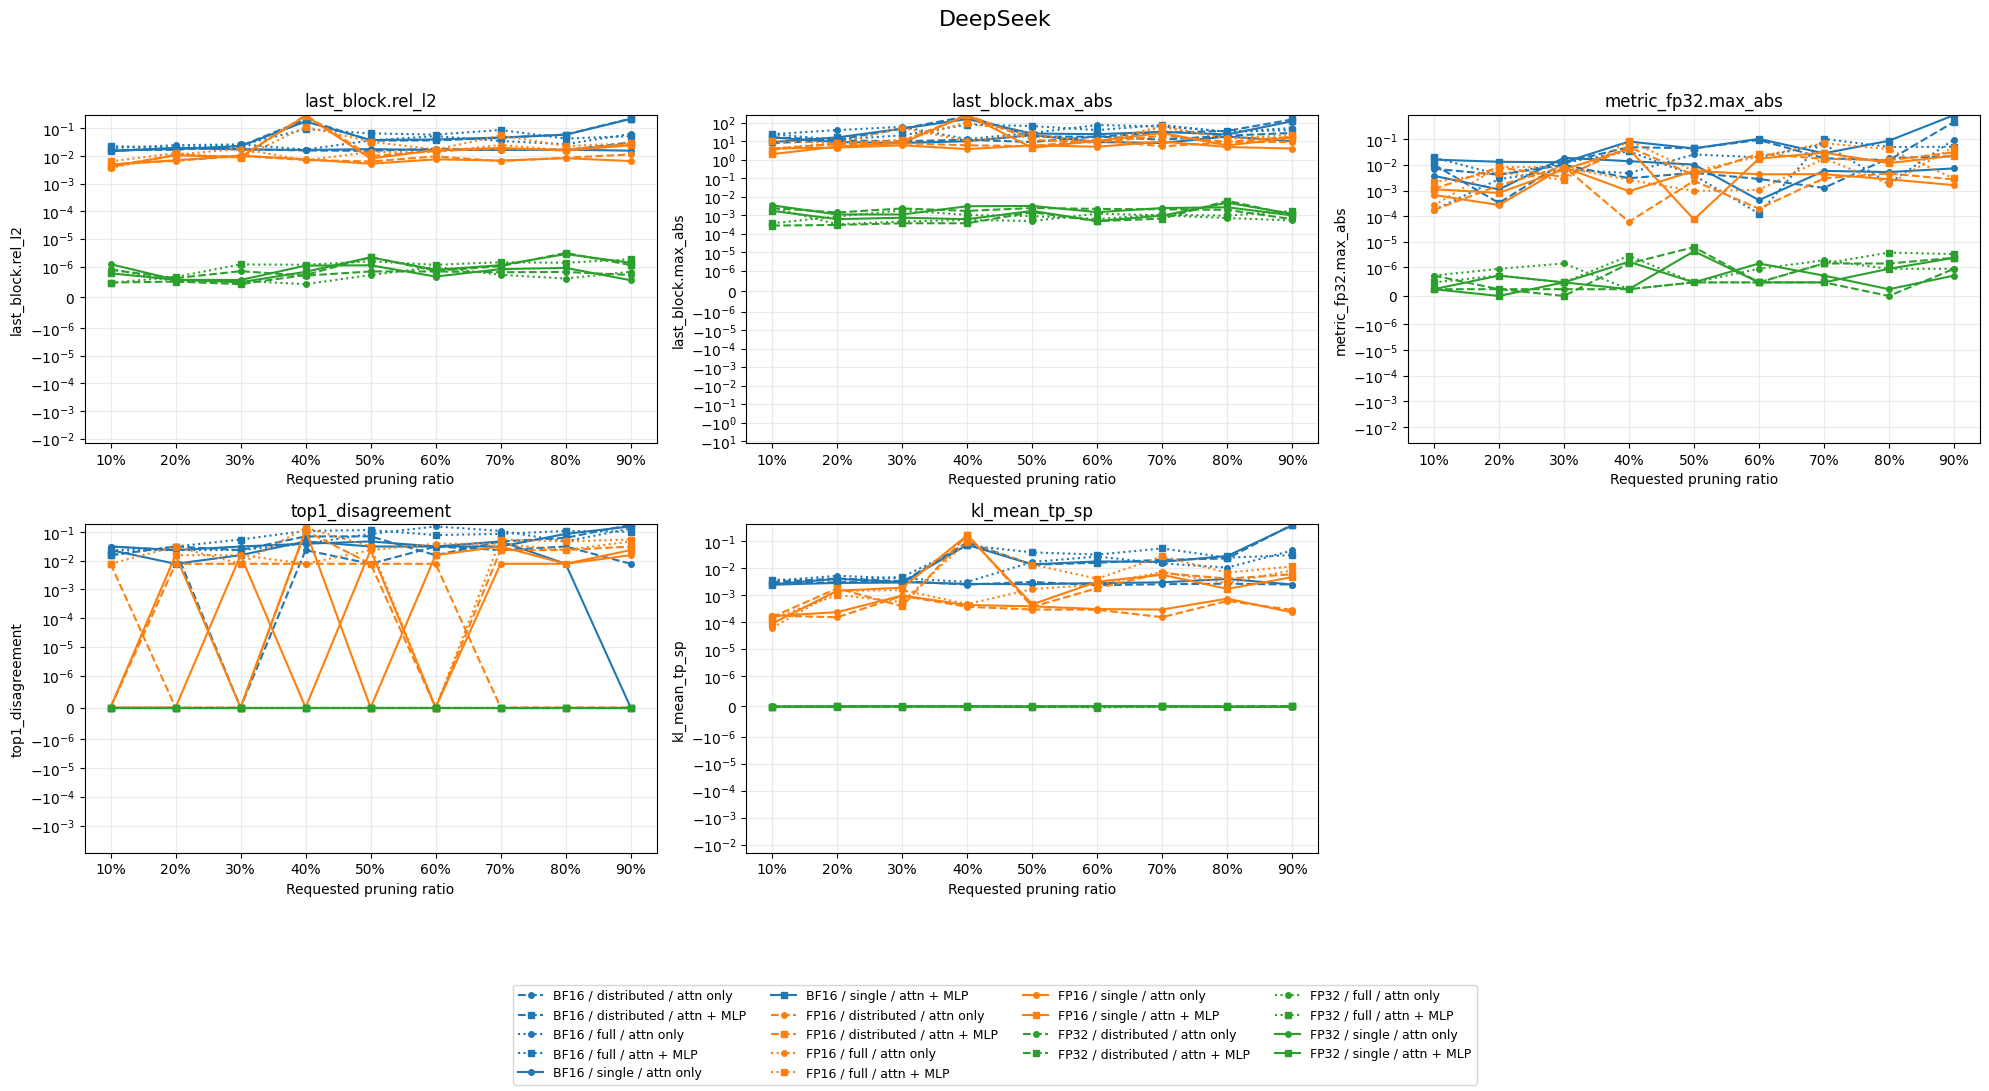

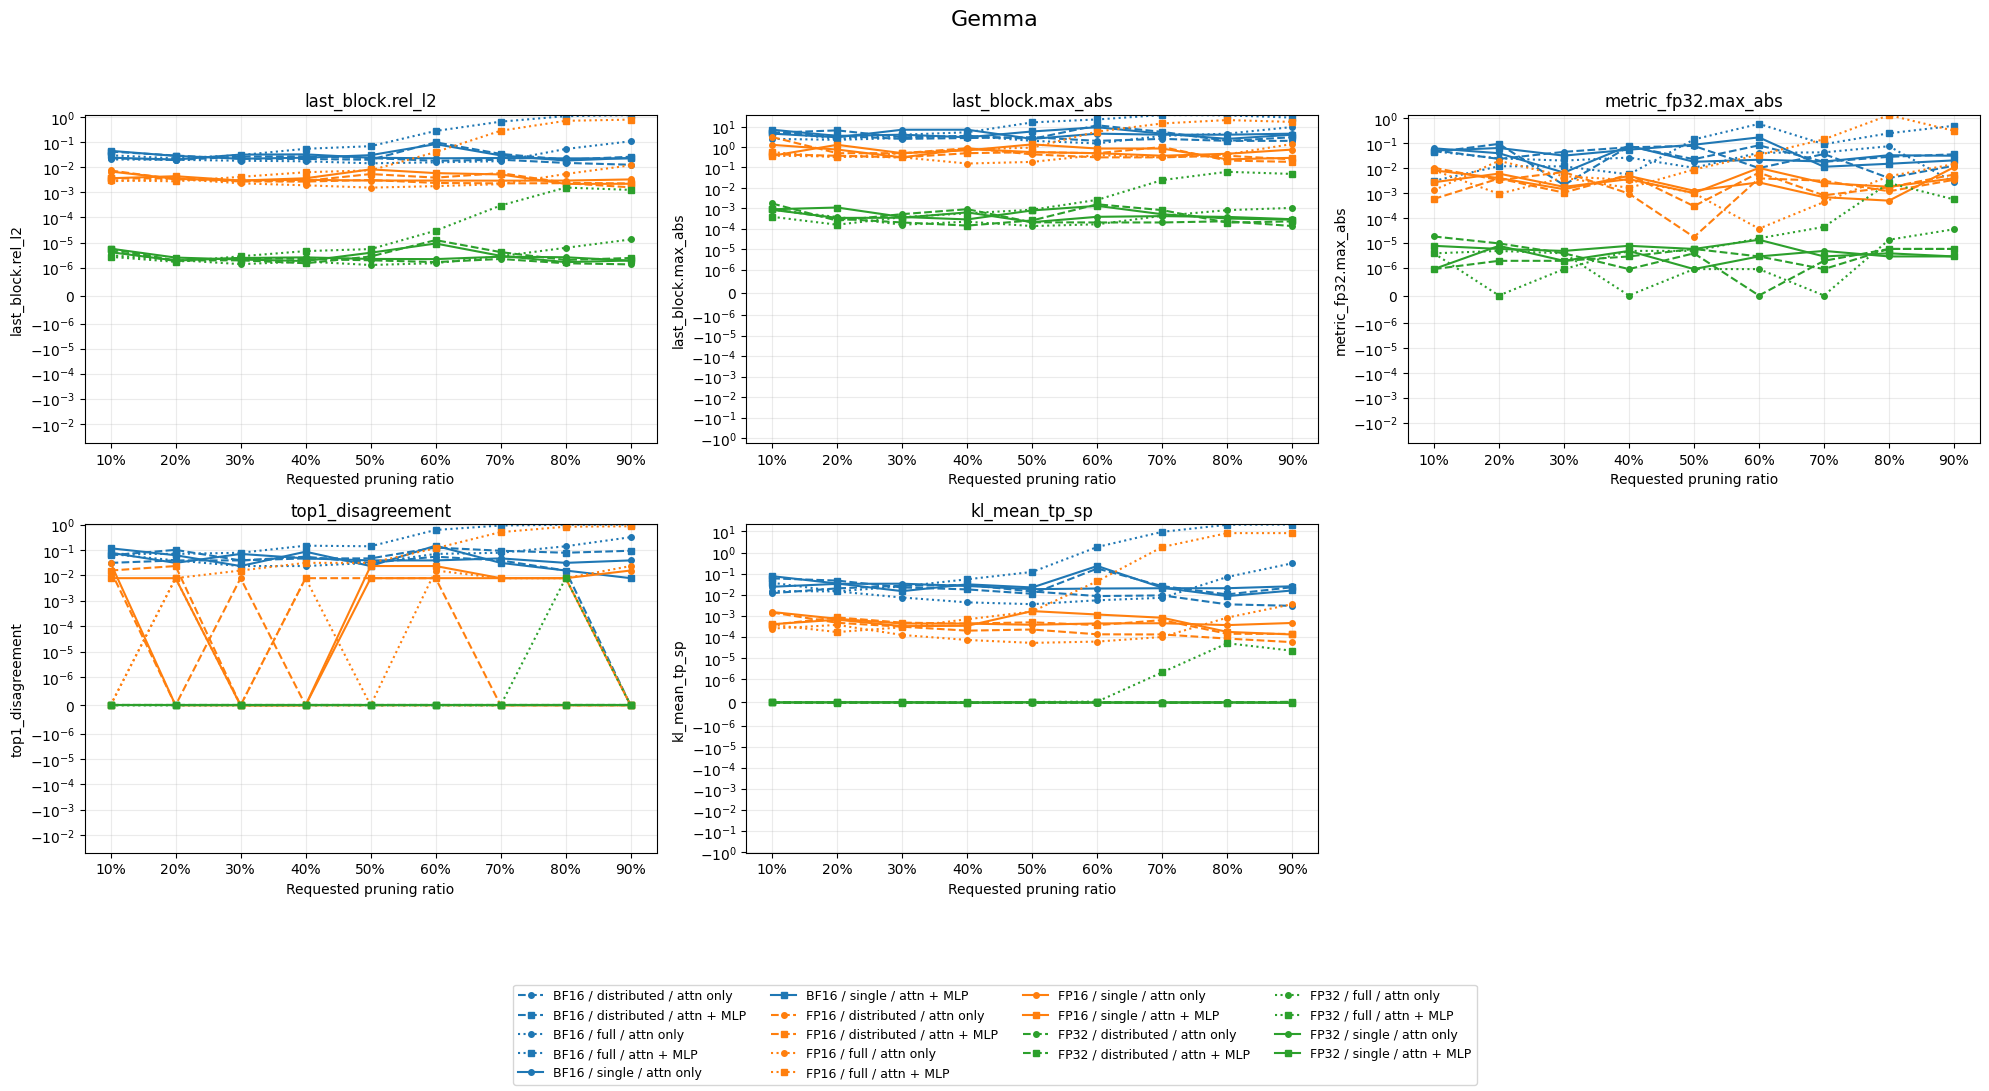

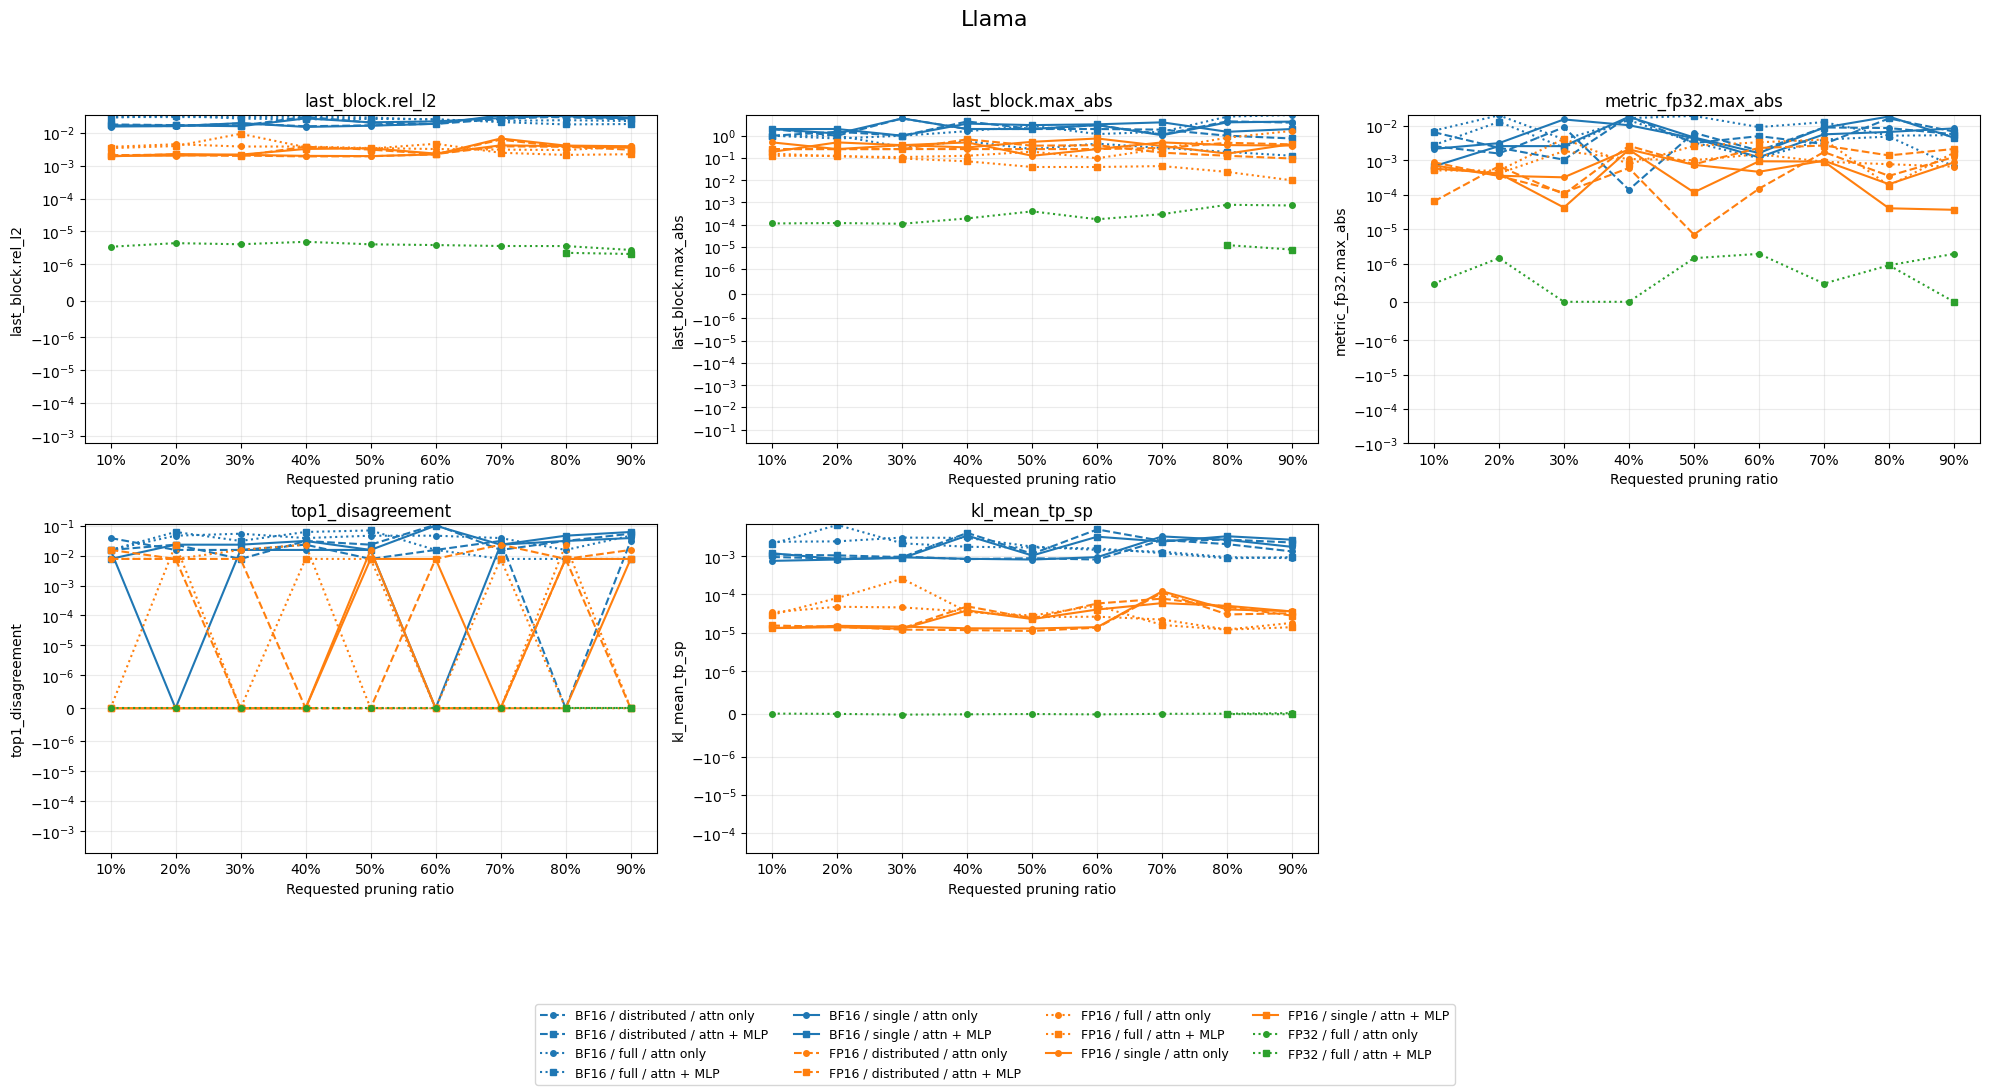

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

completed = df[df.status.eq('completed')]
metrics = ['last_block.rel_l2', 'last_block.max_abs', 'metric_fp32.max_abs', 'top1_disagreement', 'kl_mean_tp_sp']
model_titles = {'deepseek': 'DeepSeek', 'gemma': 'Gemma', 'llama': 'Llama'}
dtype_colors = {'bf16': 'tab:blue', 'fp16': 'tab:orange', 'fp32': 'tab:green'}
coverage_styles = {'single': '-', 'distributed': '--', 'full': ':'}

# Отдельная фигура и легенда для каждой модели; стили одинаковы между фигурами.
for model_name, title in model_titles.items():
    model_rows = completed[completed.model.eq(model_name)]
    if model_rows.empty:
        continue
    fig, axes = plt.subplots(2, 3, figsize=(20, 11), squeeze=False)
    axes = axes.ravel()
    for unused_ax in axes[len(metrics):]:
        fig.delaxes(unused_ax)
    axes = axes[:len(metrics)]
    fig.suptitle(title, fontsize=16)
    for (dtype, coverage, mlp), rows in model_rows.groupby(['dtype', 'coverage', 'mlp']):
        rows = rows.sort_values('ratio')
        label = f'{dtype.upper()} / {coverage} / {"attn + MLP" if mlp else "attn only"}'
        for ax, metric in zip(axes, metrics):
            ax.plot(rows.ratio, rows[metric], label=label,
                    color=dtype_colors.get(dtype), linestyle=coverage_styles.get(coverage, '-'),
                    marker='s' if mlp else 'o', markersize=4)
    for ax, metric in zip(axes, metrics):
        ax.set(xlabel='Requested pruning ratio', ylabel=metric, title=metric)
        ax.set_xticks(sorted(model_rows.ratio.unique()))
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
        ax.set_yscale('symlog', linthresh=1e-6)
        ax.grid(alpha=.25)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=9)
    fig.tight_layout(rect=(0, .16, 1, .95))
    plt.show()


In [5]:
# Полные метрики по хукам, индексы и traceback сохраняются отдельно для каждого прогона.
import json
run_id = completed.iloc[0]['id'] if len(completed) else None
if run_id:
    run = json.loads((RESULTS / f'{run_id}.json').read_text())
    display(pd.DataFrame.from_dict(run['hooks'], orient='index').drop(columns=['difference'], errors='ignore'))
    display(pd.DataFrame(run['removed']).drop(columns=['indices']))
for path in sorted(RESULTS.glob('restore_audit_*.json')):
    print(path.name, json.loads(path.read_text())['status'])


,status,max_abs,mean_abs,rmse,rel_l2,abs_l2,reference_shape,candidate_shape,reference_restored_shape,candidate_restored_shape,compared_elements,reason
blocks.0.attn.q.hook_out,OK,0.000076,1.193698e-06,3.629260e-06,2.572888e-07,0.001858,"[2, 64, 416]","[2, 64, 8, 256]","[2, 64, 2048]","[2, 64, 2048]",262144,None
blocks.0.attn.k.hook_out,OK,0.000061,8.462980e-07,2.768450e-06,1.407413e-07,0.000709,"[2, 64, 104]","[2, 64, 2, 256]","[2, 64, 512]","[2, 64, 512]",65536,None
blocks.0.attn.v.hook_out,OK,0.000244,8.273738e-07,3.100277e-06,1.736864e-07,0.000794,"[2, 64, 104]","[2, 64, 2, 256]","[2, 64, 512]","[2, 64, 512]",65536,None
blocks.0.attn.o.hook_in,OK,0.000002,1.734471e-08,5.556946e-08,2.319172e-07,0.000028,"[2, 64, 416]","[2, 64, 8, 256]","[2, 64, 2048]","[2, 64, 2048]",262144,None
blocks.0.mlp.gate.hook_out,OK,0.000007,9.850870e-08,2.953927e-07,4.135230e-07,0.000338,"[2, 64, 2048]","[2, 64, 10240]","[2, 64, 10240]","[2, 64, 10240]",1310720,None
blocks.0.mlp.in.hook_out,OK,0.000011,7.872975e-08,2.336669e-07,4.939657e-07,0.000268,"[2, 64, 2048]","[2, 64, 10240]","[2, 64, 10240]","[2, 64, 10240]",1310720,None
blocks.0.mlp.out.hook_in,OK,0.000076,2.757225e-08,2.387342e-07,4.529076e-07,0.000273,"[2, 64, 2048]","[2, 64, 10240]","[2, 64, 10240]","[2, 64, 10240]",1310720,None


,module,direction,original_size,removed,actual_ratio
0,blocks.0._original_component.self_attn._origin...,out,2048,1632,0.796875
1,blocks.0._original_component.self_attn._origin...,in,2048,1632,0.796875
2,blocks.0._original_component.self_attn._origin...,out,512,408,0.796875
3,blocks.0._original_component.self_attn._origin...,out,512,408,0.796875
4,blocks.0._original_component.mlp._original_com...,out,10240,8192,0.800000
5,blocks.0._original_component.mlp._original_com...,in,10240,8192,0.800000
6,blocks.0._original_component.mlp._original_com...,out,10240,8192,0.800000


restore_audit_deepseek_bf16.json OK
restore_audit_deepseek_fp16.json OK
restore_audit_deepseek_fp32.json OK
restore_audit_gemma_bf16.json OK
restore_audit_gemma_fp16.json OK
restore_audit_gemma_fp32.json OK
restore_audit_llama_bf16.json OK
restore_audit_llama_fp16.json OK
restore_audit_llama_fp32.json OK
